# Classification Track - Urban Bike Demand Forecasting



## Problem Statement

Predict the bike rental demand for an urban bike-sharing system using information available about weather conditions, temperature, humidity, wind speed, cloud coverage, day type, and other environmental factors.

In this classification track the task is framed as a **binary classification** problem: every hour is labelled **Low demand (0)** or **High demand (1)** depending on whether the number of rentals in that hour is at or below, or above, the median hourly count.

## Dataset

`capitalbikeshare-complete.csv`, containing 33,379 records and 16 original columns. The dataset includes bike rental demand, datetime information, weather conditions, temperature, humidity, wind speed, pressure, cloud coverage, rainfall, snowfall, holiday and working-day information.

## Notebook Map

| Section | Contents |
|:---:|:---|
| 1 | Setup, load & audit |
| 2 | Target creation (Low / High demand) |
| 3 | Exploratory data analysis |
| 4 | Cleaning |
| 5 | Feature engineering |
| 6 | Encoding, scaling & splitting (pipeline) |
| 7 | Ten classification algorithms |
| 8 | Comparative evaluation |
| 9 | Hyperparameter tuning |
| 10 | Cross-validation |
| 11 | ROC curves, feature importance & decision tree |
| 12 | Final comparison, conclusion & saved model |

## 1. Setup, Load & Audit



In [2]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Splitting, tuning, validation
from sklearn.model_selection import (
    train_test_split, GridSearchCV, RandomizedSearchCV, cross_val_score
)

# Preprocessing and pipelines
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Metrics
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay, roc_auc_score,
    roc_curve, classification_report
)

# Part A algorithms
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.svm import SVC

# Part B algorithms
from sklearn.ensemble import (
    RandomForestClassifier, AdaBoostClassifier,
    GradientBoostingClassifier, BaggingClassifier
)
from sklearn.neural_network import MLPClassifier

# Reproducibility and plot style
RANDOM_STATE = 42
sns.set_palette("colorblind")
sns.set_style("whitegrid")

print("Libraries imported successfully.")
print("Random State:", RANDOM_STATE)

Libraries imported successfully.
Random State: 42


### 1.1 Load and audit the dataset



In [3]:
df = pd.read_csv("capitalbikeshare-complete.csv", encoding="utf-8-sig")

print("Shape:", df.shape)
print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
missing = df.isna().sum()
print(pd.DataFrame({"missing": missing, "percent": (missing / len(df) * 100).round(2)}))

print("\nDuplicate rows:", df.duplicated().sum())
df.head()

Shape: (33379, 16)

Data types:
datetime            str
count             int64
holiday           int64
workingday        int64
temp            float64
feels_like      float64
temp_min        float64
temp_max        float64
pressure          int64
humidity          int64
wind_speed      float64
wind_deg          int64
rain_1h         float64
snow_1h         float64
clouds_all        int64
weather_main        str
dtype: object

Missing values:
              missing  percent
datetime            0     0.00
count               0     0.00
holiday             0     0.00
workingday          0     0.00
temp                0     0.00
feels_like          0     0.00
temp_min            0     0.00
temp_max            0     0.00
pressure            0     0.00
humidity            0     0.00
wind_speed          0     0.00
wind_deg            0     0.00
rain_1h         26608    79.71
snow_1h         33053    99.02
clouds_all          0     0.00
weather_main        0     0.00

Duplicate rows: 0


,datetime,count,holiday,workingday,temp,feels_like,temp_min,temp_max,pressure,humidity,wind_speed,wind_deg,rain_1h,snow_1h,clouds_all,weather_main
0,2018-01-01 00:00,34,1,0,-7.17,-12.73,-8.56,-7.09,1030,53,3.6,310,NaN,NaN,20,Clouds
1,2018-01-01 01:00,49,1,0,-7.35,-13.81,-9.03,-7.15,1030,49,4.6,310,NaN,NaN,1,Clear
2,2018-01-01 02:00,37,1,0,-7.88,-14.05,-9.03,-7.69,1031,52,4.1,310,NaN,NaN,1,Clear
3,2018-01-01 03:00,9,1,0,-8.10,-14.32,-9.36,-7.89,1031,49,4.1,310,NaN,NaN,1,Clear
4,2018-01-01 04:00,12,1,0,-8.19,-14.43,-9.46,-8.09,1031,49,4.1,330,NaN,NaN,1,Clear


#### Observations: dataset audit

- The dataset has **33,379 hourly records and 16 columns**: 14 numeric columns, plus `datetime` and `weather_main`, which are text.
- `datetime` is stored as text, so it must be converted to a real datetime before time features can be extracted (done in Section 4).
- Only two columns have missing values: `rain_1h` (26,608 missing, 79.71%) and `snow_1h` (33,053 missing, 99.02%). In the first rows these are blank in dry, clear hours, so a missing value means "no rain/snow was recorded", not lost data.
- There are **no exact duplicate rows**. Repeated timestamps are examined separately in Section 4.

---
## 2. Target Creation

The dataset has no class label, only the continuous ride count `count`. A binary target `demand` is therefore created:

| Class | Definition |
|:---|:---|
| Low demand (0) | `count` <= median hourly count |
| High demand (1) | `count` > median hourly count |

**Why the median?** It splits the data into two almost equal classes. This avoids class imbalance, so accuracy is a fair metric, stratified splitting is straightforward, and ROC-AUC takes its standard binary form.

`count` will be removed from the features later, because it directly defines the target and keeping it would be data leakage.

Median hourly rides: 236.0

Target class distribution:
          class  count  percent
 Low demand (0)  16692    50.01
High demand (1)  16687    49.99


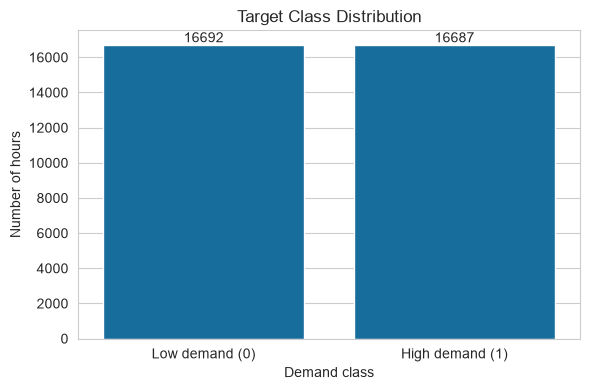

In [4]:
# Binary target: Low demand (0) vs High demand (1), split at the median of 'count'
median_count = df["count"].median()
print("Median hourly rides:", median_count)

df["demand"] = (df["count"] > median_count).astype(int)

# Class distribution
dist = df["demand"].value_counts().sort_index()
dist_df = pd.DataFrame({
    "class": ["Low demand (0)", "High demand (1)"],
    "count": dist.values,
    "percent": (dist.values / len(df) * 100).round(2)
})
print("\nTarget class distribution:")
print(dist_df.to_string(index=False))

# Plot
plt.figure(figsize=(6, 4))
ax = sns.countplot(x="demand", data=df)
ax.set_xticklabels(["Low demand (0)", "High demand (1)"])
ax.bar_label(ax.containers[0])
plt.title("Target Class Distribution")
plt.xlabel("Demand class")
plt.ylabel("Number of hours")
plt.tight_layout()
plt.show()

#### Observations: target class distribution

- The median is **236 rides per hour**.
- Low demand has 16,692 hours (50.01%) and High demand has 16,687 hours (49.99%), so the classes are **almost perfectly balanced**. No resampling or class weights are needed.
- Because of the balance, accuracy is a trustworthy metric here and weighted F1 will stay close to accuracy for most models.

---
## 3. Exploratory Data Analysis

### 3.1 Distribution of every feature

Histograms of all 13 numeric columns show the shape, spread and skew of each feature. Note that `rain_1h` and `snow_1h` are plotted only for the hours where a value was recorded.

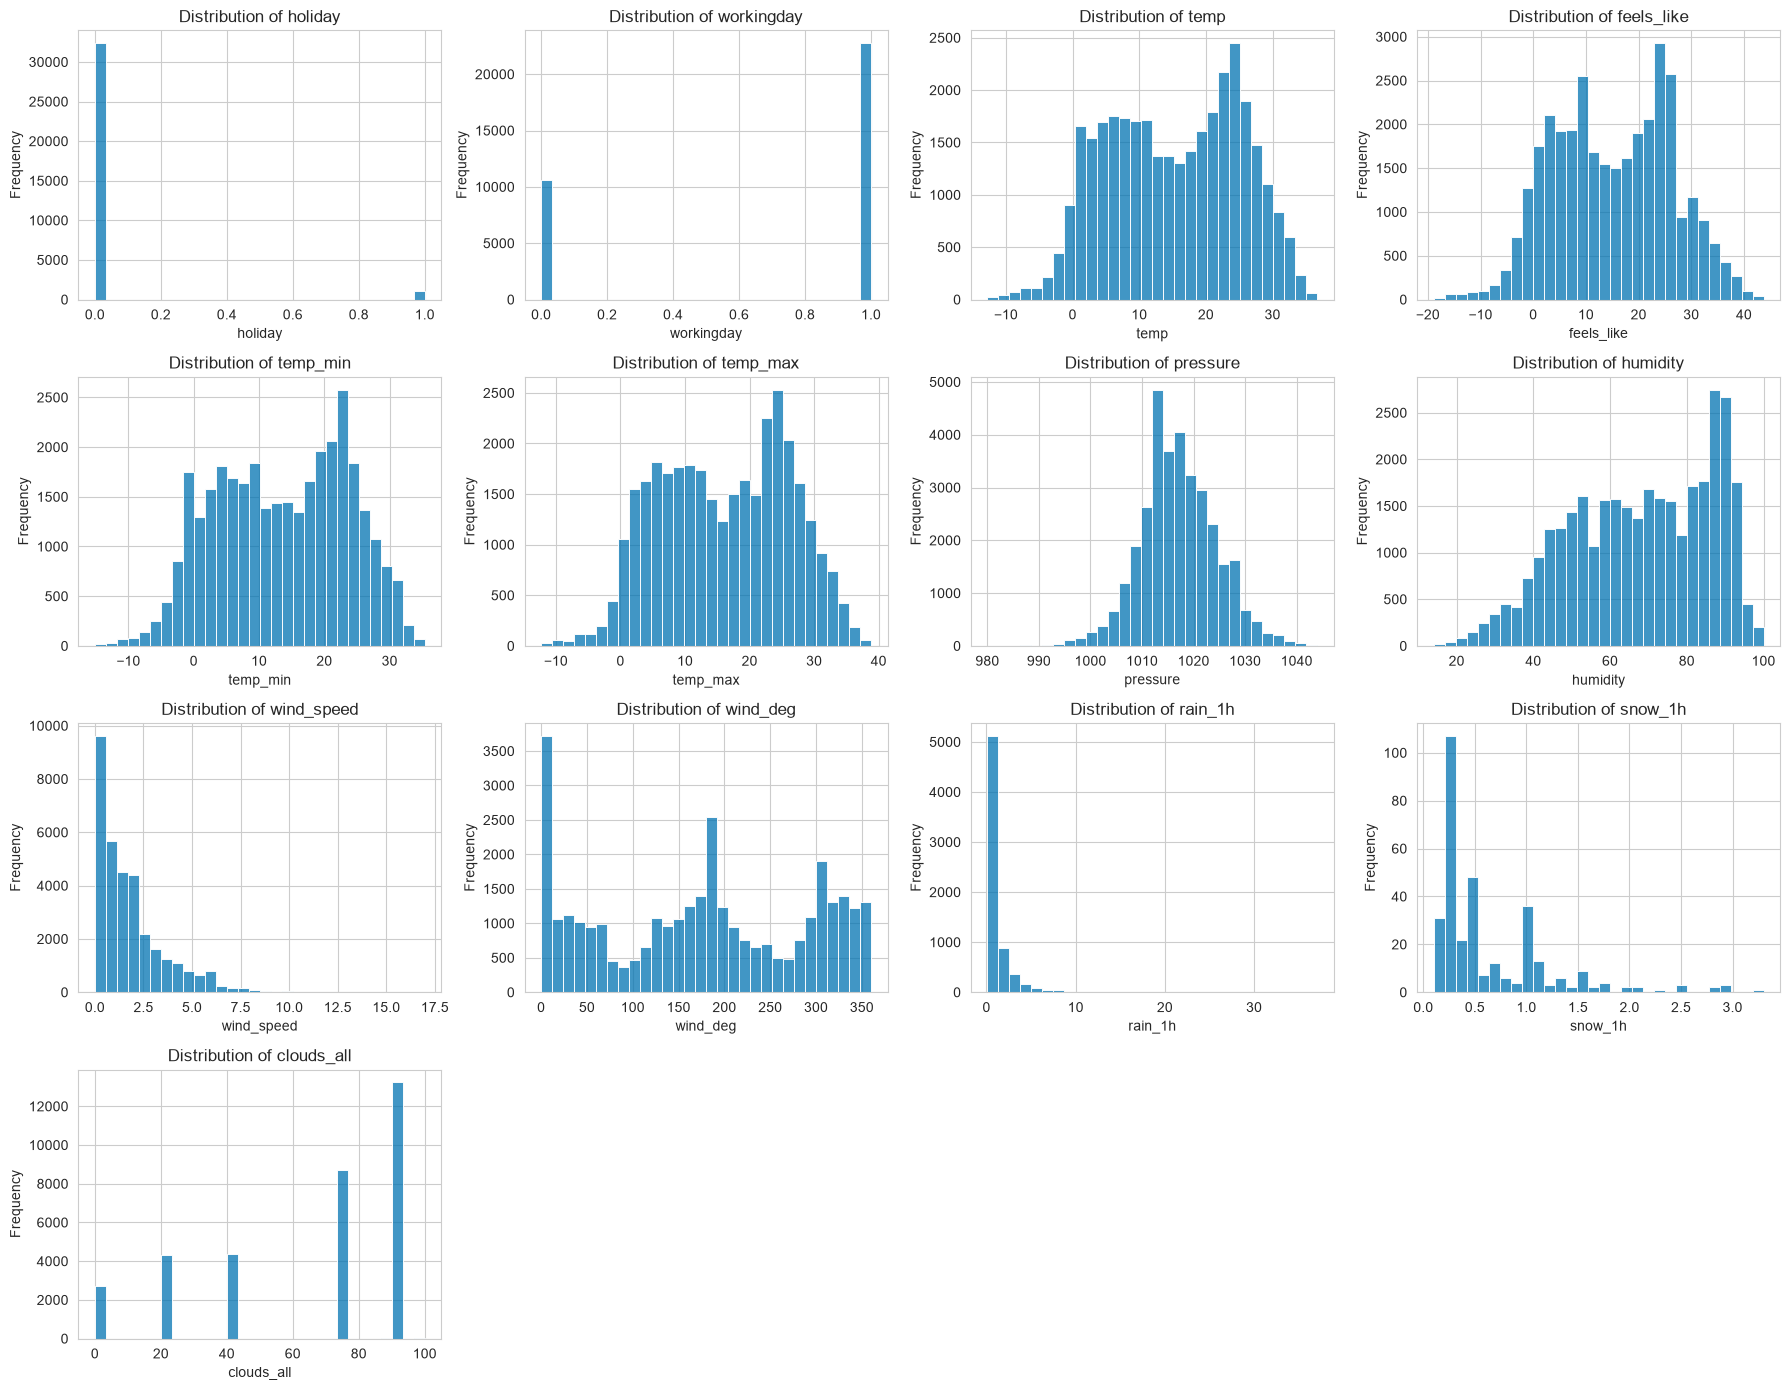

In [5]:
num_cols = ["holiday", "workingday", "temp", "feels_like", "temp_min", "temp_max",
            "pressure", "humidity", "wind_speed", "wind_deg",
            "rain_1h", "snow_1h", "clouds_all"]

fig, axes = plt.subplots(4, 4, figsize=(18, 14))
axes = axes.flatten()

for i, col in enumerate(num_cols):
    sns.histplot(df[col].dropna(), bins=30, ax=axes[i])
    axes[i].set_title(f"Distribution of {col}")
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Frequency")

# hide unused subplots
for j in range(len(num_cols), len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()

#### Observations: feature distributions

- **holiday / workingday:** both are binary. About 68% of hours fall on working days, and holidays are rare (about 3%).
- **temp, feels_like, temp_min, temp_max:** all four have the same two-peaked shape (one group of hours around 5-10 C and another around 24 C, reflecting winter and summer). They look like copies of one signal, which the correlation heatmap confirms below.
- **pressure:** roughly bell-shaped and centred near 1015 hPa, with a few extreme low and high readings.
- **humidity:** skewed to the left, with most hours between 50% and 95% and a peak near 88-90%.
- **wind_speed:** strongly right-skewed. Most hours are below 3 m/s, with a thin tail up to about 17 m/s.
- **wind_deg:** spread over the full compass, with spikes at 0 degrees, around 180-190 and around 300-310.
- **rain_1h / snow_1h:** very right-skewed. Most recorded rain hours are under about 2 mm (with a rare maximum of 37 mm), and snow is recorded in only 326 hours, mostly below 1 mm. These long tails motivate the log transform in Section 4.
- **clouds_all:** takes only a few discrete values (0, 20, 40, 75, 90), and most hours are heavily clouded (75-90%).

### 3.2 Weather condition (`weather_main`)

The only categorical feature is `weather_main`. Its category counts show how common each condition is.

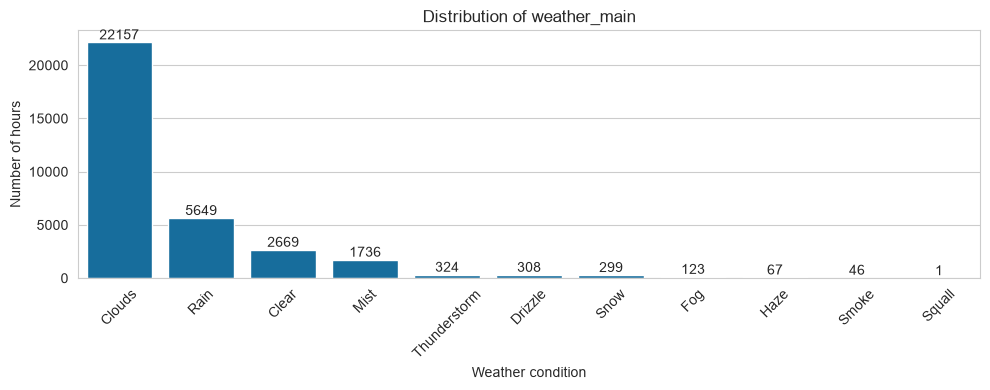

In [6]:
plt.figure(figsize=(10, 4))
order = df["weather_main"].value_counts().index
ax = sns.countplot(x="weather_main", data=df, order=order)
ax.bar_label(ax.containers[0])
plt.title("Distribution of weather_main")
plt.xlabel("Weather condition")
plt.ylabel("Number of hours")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

#### Observations: weather categories

- **Clouds dominates** with 22,157 hours (about 66%), followed by Rain (5,649), Clear (2,669) and Mist (1,736).
- Thunderstorm (324), Drizzle (308), Snow (299) and Fog (123) are rare.
- Haze (67), Smoke (46) and Squall (1) are so rare that a one-hot encoder would create nearly empty columns. They are merged into an "Other" group during cleaning (Section 4).
- The strong imbalance means models see very few examples of unusual weather, so weather type alone is unlikely to drive predictions.

### 3.3 Correlation analysis

The heatmap shows the pairwise Pearson correlation between the numeric features and the target `demand`.

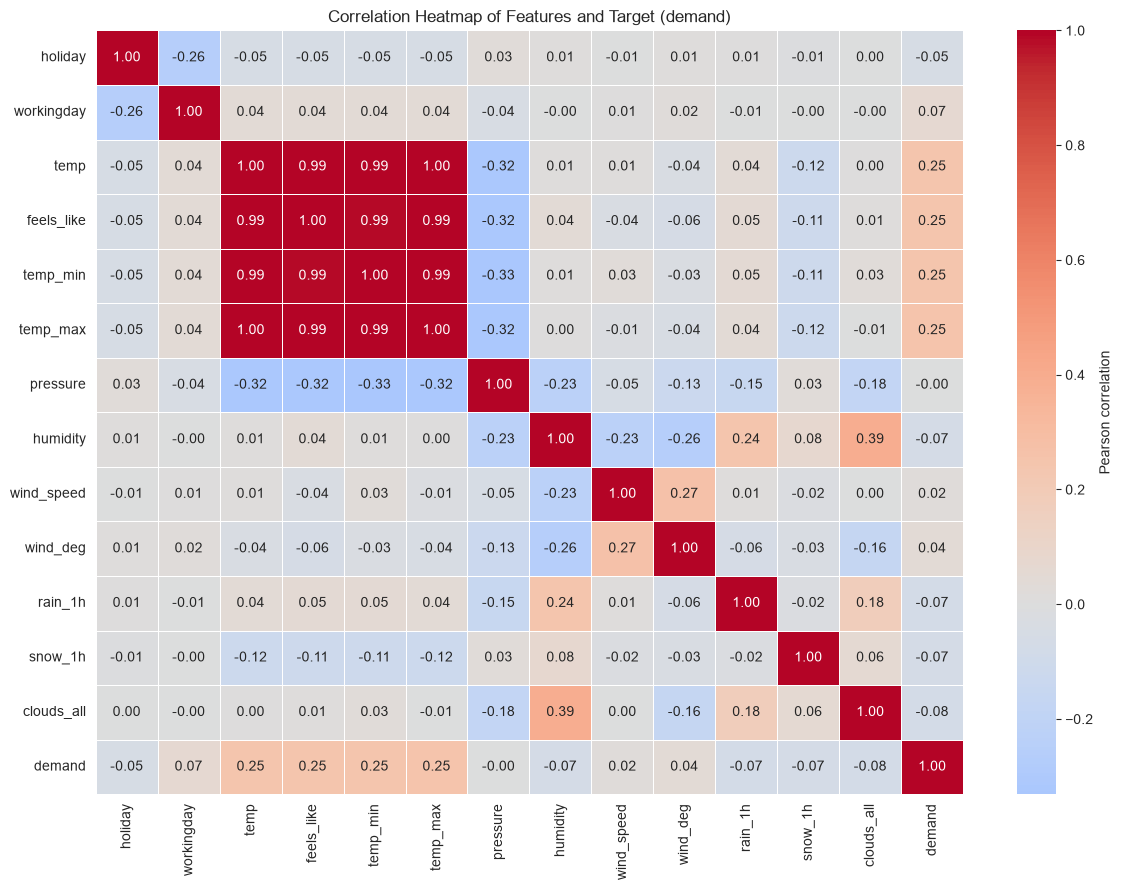

In [7]:
corr_cols = num_cols + ["demand"]

# Work on a copy: NaN in rain_1h / snow_1h means "no precipitation recorded",
# so treat it as 0 for the correlation only (df itself is cleaned later in Section 4)
corr_df = df[corr_cols].copy()
corr_df[["rain_1h", "snow_1h"]] = corr_df[["rain_1h", "snow_1h"]].fillna(0)
corr = corr_df.corr()

plt.figure(figsize=(12, 9))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            linewidths=0.5, cbar_kws={"label": "Pearson correlation"})
plt.title("Correlation Heatmap of Features and Target (demand)")
plt.tight_layout()
plt.show()

#### Observations: correlation heatmap

- **temp, feels_like, temp_min and temp_max are almost perfectly correlated** (0.99-1.00). They are redundant, and keeping all four would add multicollinearity (harmful for Logistic Regression and Naive Bayes) without adding information. Only `temp` is kept in Section 5.
- Weather variables are also related to each other: pressure falls as temperature rises (about -0.32), and humidity rises with cloud cover (0.39). Holiday and working day are negatively related (-0.26), as expected, since holidays are non-working days.
- Rain and snow are filled with 0 (no precipitation recorded) for this plot only, so every cell can be computed. `rain_1h` and `snow_1h` are almost uncorrelated with each other (-0.02), because rain and snow rarely happen together, and rain is mildly linked to humidity (0.24) and cloud cover (0.18).
- The target column shows that **no single raw feature correlates strongly with demand**: temperature is the highest at about 0.25 and everything else is below 0.08 in absolute value.

In [8]:
print("Correlation of each feature with demand (sorted):")
print(corr["demand"].drop("demand").sort_values(ascending=False).round(3))

Correlation of each feature with demand (sorted):
temp_max      0.254
temp          0.250
temp_min      0.247
feels_like    0.246
workingday    0.065
wind_deg      0.043
wind_speed    0.020
pressure     -0.001
holiday      -0.053
snow_1h      -0.066
humidity     -0.069
rain_1h      -0.073
clouds_all   -0.076
Name: demand, dtype: float64


#### Observations: correlation with the target

- Warmer hours tend to be High demand: `temp_max` (0.254), `temp` (0.250), `temp_min` (0.247) and `feels_like` (0.246).
- Cloudier, more humid, snowy and rainy hours lean slightly towards Low demand: `clouds_all` (-0.076), `rain_1h` (-0.073), `humidity` (-0.069) and `snow_1h` (-0.066).
- `pressure` (-0.001) and `wind_speed` (0.020) are essentially uncorrelated with demand.
- Overall, the **linear correlation of raw weather features with demand is weak**. This suggests that time-of-day features, which are not yet in the dataset, will matter far more, which motivates the feature engineering in Section 5.

### 3.4 Feature vs target relationships

The scatter plots compare temperature and humidity with the actual hourly ride count, coloured by demand class. A random sample of 5,000 hours is used so the points stay readable.

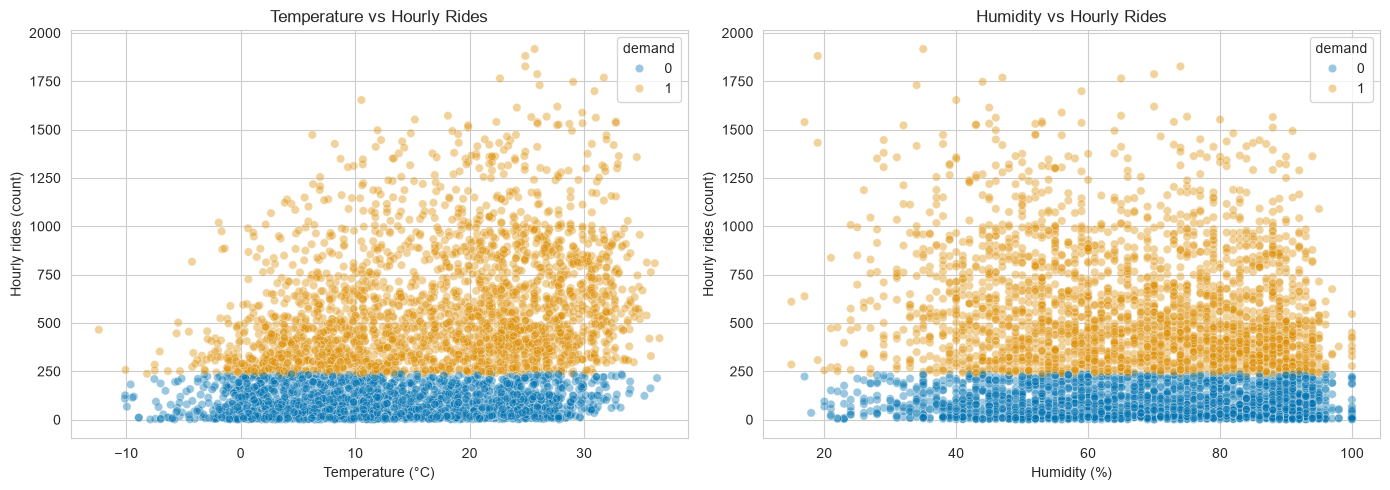

In [9]:
sample = df.sample(5000, random_state=RANDOM_STATE)  # sample for readable plots

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.scatterplot(data=sample, x="temp", y="count", hue="demand",
                alpha=0.4, ax=axes[0])
axes[0].set_title("Temperature vs Hourly Rides")
axes[0].set_xlabel("Temperature (°C)")
axes[0].set_ylabel("Hourly rides (count)")

sns.scatterplot(data=sample, x="humidity", y="count", hue="demand",
                alpha=0.4, ax=axes[1])
axes[1].set_title("Humidity vs Hourly Rides")
axes[1].set_xlabel("Humidity (%)")
axes[1].set_ylabel("Hourly rides (count)")

plt.tight_layout()
plt.show()

#### Observations: temperature and humidity vs rides

- **Temperature:** below roughly 0 C almost every hour is Low demand (blue). From about 5 C upward, High-demand hours (orange) appear and become the majority, and the busiest hours (above 1,500 rides) occur at about 22-32 C. Warm weather therefore raises the chance of high demand.
- At every temperature both classes overlap heavily, so temperature alone cannot separate the classes. This matches its modest correlation (about 0.25).
- **Humidity:** both classes are spread across the whole 20-100% range with no visible trend, matching the very weak correlation (-0.07). Humidity is a weak predictor on its own.
- The flat boundary at 236 rides is simply the median threshold that defines the colours.

### 3.5 Demand by hour of day

The bar chart shows, for each hour of the day, the share of hours that are High demand. The dashed line marks the overall rate of 50%.

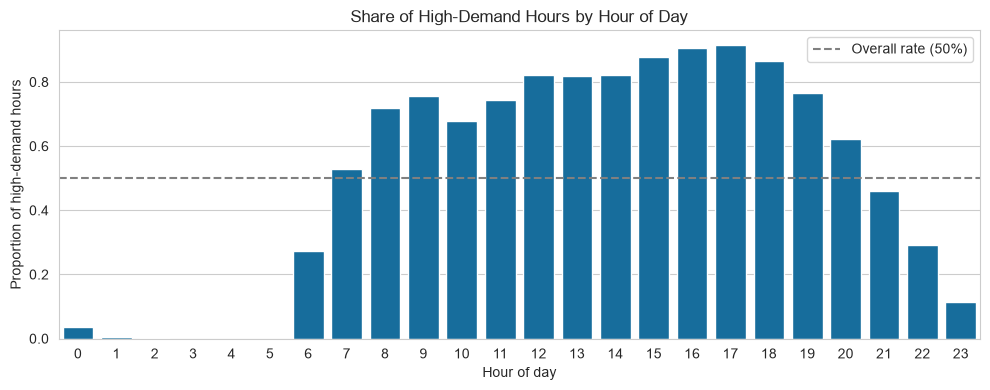

In [10]:
hour = pd.to_datetime(df["datetime"]).dt.hour
hourly_rate = df.groupby(hour)["demand"].mean()

plt.figure(figsize=(10, 4))
sns.barplot(x=hourly_rate.index, y=hourly_rate.values, color=sns.color_palette("colorblind")[0])
plt.axhline(0.5, color="gray", linestyle="--", label="Overall rate (50%)")
plt.title("Share of High-Demand Hours by Hour of Day")
plt.xlabel("Hour of day")
plt.ylabel("Proportion of high-demand hours")
plt.legend()
plt.tight_layout()
plt.show()

#### Observations: demand by hour of day

- **Night (00:00-05:00):** almost no High-demand hours (about 3% at midnight and roughly 0% from 01:00 to 05:00).
- **Morning ramp-up:** about 27% at 06:00, crossing 50% at 07:00 and reaching 72-75% at 08:00-09:00 (morning commute).
- **Midday and afternoon:** about 82% around noon, rising to the **daily peak of about 88-91% between 15:00 and 18:00**, with the maximum at 17:00. The evening peak is higher than the morning one.
- **Evening decline:** 76% at 19:00, 62% at 20:00, 46% at 21:00, 29% at 22:00 and only 11% at 23:00.
- This pattern is far stronger than any raw weather feature, so hour-based features will be the most important engineered features.

#### Key EDA takeaways

- The classes are balanced, so no resampling is needed.
- Hour of day is the strongest driver of demand, followed by temperature. Humidity, wind, pressure and cloud cover are weak on their own.
- The four temperature columns are redundant, and rain/snow are heavily skewed with mostly missing values. Both are handled in the next sections.

---
## 4. Data Cleaning

### 4.1 Duplicates and value ranges

The cell checks for duplicate rows and duplicate timestamps, converts `datetime` into a proper datetime type, and checks that every value is physically possible.

In [11]:
# Duplicates
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate timestamps:", df["datetime"].duplicated().sum())

# Convert datetime (needed later for feature engineering)
df["datetime"] = pd.to_datetime(df["datetime"])

# Sanity check: are the values physically valid?
print("\nValue ranges:")
print(df[["temp", "pressure", "humidity", "wind_speed", "wind_deg", "clouds_all"]].agg(["min", "max"]).T)

Duplicate rows: 0
Duplicate timestamps: 1963

Value ranges:
               min      max
temp        -12.79    36.71
pressure    980.00  1044.00
humidity     14.00   100.00
wind_speed    0.00    16.98
wind_deg      0.00   360.00
clouds_all    0.00   100.00


#### Observations: duplicates and validity

- There are **0 exact duplicate rows**.
- However, **1,963 rows repeat a timestamp**: 1,686 distinct hours appear 2 to 4 times each (3,649 rows in total). In every such hour the ride count is the same in all copies and only `weather_main` differs. For example, 2018-01-04 05:00 appears once as "Snow" and once as "Mist". So these are not errors; the same hour was reported under several weather labels. The rows were kept, but this matters for the train/test split (see the limitations in Section 12).
- All value ranges are physically valid: temperature -12.79 to 36.71 C, pressure 980-1044 hPa, humidity 14-100%, wind speed 0-16.98 m/s, wind direction 0-360 degrees and cloud cover 0-100%. There are no impossible values to remove.

### 4.2 Outlier detection (IQR method)

A value is flagged as an outlier if it lies more than 1.5 x IQR below the first quartile or above the third quartile. `rain_1h` and `snow_1h` are checked on the hours where they were recorded, since their other values are still missing at this point. Box plots show the same information visually.

             lower    upper  n_outliers  percent
temp        -18.55    49.21         0.0     0.00
pressure    997.00  1037.00       304.0     0.91
humidity      6.50   130.50         0.0     0.00
wind_speed   -2.77     5.82      1099.0     3.29
rain_1h      -1.33     2.88       661.0     9.76
snow_1h      -0.88     2.12        10.0     3.07


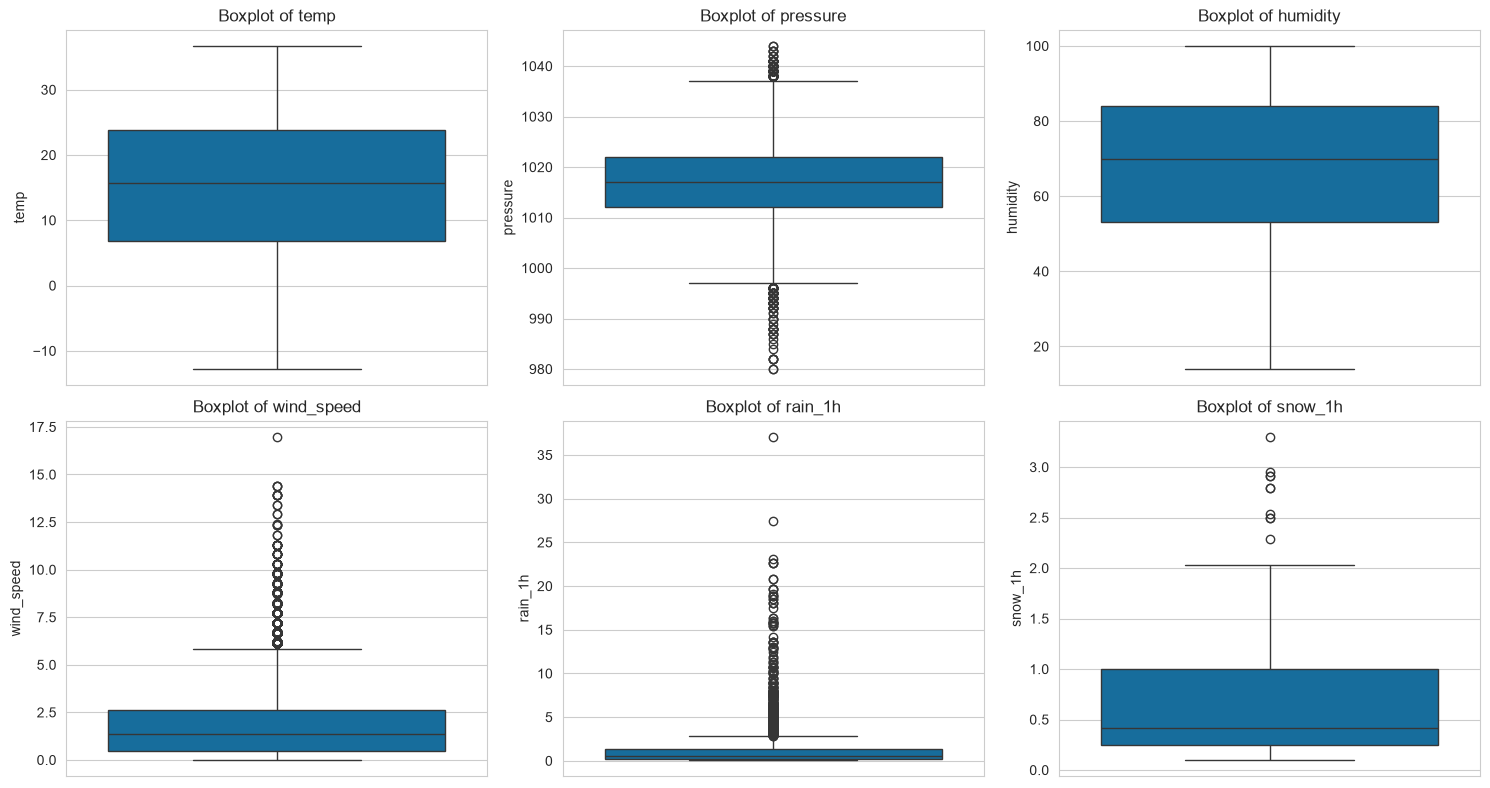

In [12]:
def iqr_outliers(series):
    s = series.dropna()
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = ((s < lower) | (s > upper)).sum()
    return pd.Series({"lower": round(lower, 2), "upper": round(upper, 2),
                      "n_outliers": n_out, "percent": round(n_out / len(s) * 100, 2)})

check_cols = ["temp", "pressure", "humidity", "wind_speed", "rain_1h", "snow_1h"]
print(pd.DataFrame({c: iqr_outliers(df[c]) for c in check_cols}).T)

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flatten(), check_cols):
    sns.boxplot(y=df[col].dropna(), ax=ax)
    ax.set_title(f"Boxplot of {col}")
    ax.set_ylabel(col)
plt.tight_layout()
plt.show()

#### Observations: outliers

| Feature | Outliers | Share |
|:---|---:|---:|
| temp | 0 | 0.00% |
| humidity | 0 | 0.00% |
| pressure | 304 | 0.91% |
| wind_speed | 1,099 | 3.29% |
| rain_1h (recorded hours) | 661 | 9.76% |
| snow_1h (recorded hours) | 10 | 3.07% |

- Temperature and humidity have no outliers.
- Pressure has outliers on both sides (storm lows near 980 hPa and high-pressure days above 1037 hPa).
- Wind speed has a long upper tail reaching about 17 m/s, and rain has a very long tail, with a few extreme downpours up to 37 mm in one hour.
- These values are **real weather events, not measurement errors**, so deleting them would remove genuine (often low-demand) hours. They are kept, and the skew of rain and snow is reduced with a log transform in the next step. Wind and pressure outliers are left unchanged because the scaler and the tree-based models handle them well.

### 4.3 Missing values and outlier treatment

- **Missing values:** a missing `rain_1h` or `snow_1h` means no precipitation was recorded, so both are filled with **0**. A constant fill uses no information from the test set, so it cannot leak.
- **Outlier treatment:** `rain_1h` and `snow_1h` are transformed with `log1p`, which compresses the long right tail while keeping every observation.

In [13]:
# Missing values: NaN in rain_1h / snow_1h means no precipitation was recorded
print("Before:", df[["rain_1h", "snow_1h"]].isna().sum().to_dict())
df[["rain_1h", "snow_1h"]] = df[["rain_1h", "snow_1h"]].fillna(0)
print("After: ", df[["rain_1h", "snow_1h"]].isna().sum().to_dict())

# Outlier treatment: keep the real extreme values, but reduce their skew with log1p
df["rain_1h"] = np.log1p(df["rain_1h"])
df["snow_1h"] = np.log1p(df["snow_1h"])

Before: {'rain_1h': 26608, 'snow_1h': 33053}
After:  {'rain_1h': 0, 'snow_1h': 0}


#### Observations: missing values and skew

- All 26,608 missing rain values and 33,053 missing snow values are now 0, so the dataset has **no missing values** left in these columns.
- After `log1p`, a 37 mm storm is no longer 100 times larger than light drizzle, so it does not dominate distance-based and gradient-based models.

### 4.4 Rare weather categories

Categories with fewer than 100 hours (Squall, Smoke, Haze) are merged into a single "Other" group so that the one-hot encoder does not create almost empty columns. Fog (123 hours) is large enough to stay separate.

In [14]:
rare = ["Squall", "Smoke", "Haze"]
df["weather_main"] = df["weather_main"].replace(rare, "Other")

print(df["weather_main"].value_counts())
print("\nTotal missing values left:", df.isna().sum().sum())

weather_main
Clouds          22157
Rain             5649
Clear            2669
Mist             1736
Thunderstorm      324
Drizzle           308
Snow              299
Fog               123
Other             114
Name: count, dtype: int64

Total missing values left: 0


#### Observations: weather categories after merging

- The new "Other" group holds **114 hours** (1 + 46 + 67), and the remaining categories are unchanged.
- The total number of missing values in the dataframe is now **0**.

#### Cleaning summary

| Issue | Finding | Action |
|:---|:---|:---|
| Missing values | `rain_1h`: 26,608, `snow_1h`: 33,053 | Filled with 0 (no precipitation recorded) |
| Exact duplicate rows | 0 | None needed |
| Repeated timestamps | 1,963 rows (1,686 hours listed 2-4 times, differing only in `weather_main`) | Kept; noted as a limitation |
| Outliers (IQR) | wind 3.29%, pressure 0.91%, rain 9.76%, snow 3.07% | Kept (real events); `log1p` applied to rain and snow |
| Rare categories | Squall (1), Smoke (46), Haze (67) | Merged into "Other" (114 hours) |
| Invalid values | None | None needed |

---
## 5. Feature Engineering

### 5.1 Time-based features

The raw weather columns correlate only weakly with demand, while the hour-of-day plot showed a strong daily pattern. New features are therefore built from the `datetime` column:

| Feature | Built from | Why it may help |
|:---|:---|:---|
| `hour` | Hour of the timestamp (0-23) | Captures the strong daily demand pattern (very low at night, peak around 15:00-18:00) |
| `day_of_week` | Monday = 0 ... Sunday = 6 | Weekday and weekend usage differ |
| `month` | 1-12 | Captures seasonal effects |
| `year` | 2018-2021 | Captures long-term change in usage over the years |
| `is_weekend` | `day_of_week` >= 5 | Direct weekend flag |
| `is_rush_hour` | Hours 7-9 and 16-19 on working days | Commuter peaks expressed as one binary flag, so even simple models can use them |
| `hour_sin`, `hour_cos` | sin and cos of 2 x pi x hour / 24 | Hour is circular: 23:00 and 00:00 are neighbours, but the numbers 23 and 0 are far apart. This encoding preserves that closeness |

In [15]:
dt = df["datetime"].dt

df["hour"] = dt.hour
df["day_of_week"] = dt.dayofweek          # Monday = 0 ... Sunday = 6
df["month"] = dt.month
df["year"] = dt.year
df["is_weekend"] = (df["day_of_week"] >= 5).astype(int)

# Commuter rush hours on working days
df["is_rush_hour"] = (df["hour"].isin([7, 8, 9, 16, 17, 18, 19]) &
                      (df["workingday"] == 1)).astype(int)

# Cyclical encoding of hour (so 23:00 and 00:00 are treated as neighbours)
df["hour_sin"] = np.sin(2 * np.pi * df["hour"] / 24)
df["hour_cos"] = np.cos(2 * np.pi * df["hour"] / 24)

df[["datetime", "hour", "day_of_week", "month", "year",
    "is_weekend", "is_rush_hour", "hour_sin", "hour_cos"]].head()

,datetime,hour,day_of_week,month,year,is_weekend,is_rush_hour,hour_sin,hour_cos
0,2018-01-01 00:00:00,0,0,1,2018,0,0,0.000000,1.000000
1,2018-01-01 01:00:00,1,0,1,2018,0,0,0.258819,0.965926
2,2018-01-01 02:00:00,2,0,1,2018,0,0,0.500000,0.866025
3,2018-01-01 03:00:00,3,0,1,2018,0,0,0.707107,0.707107
4,2018-01-01 04:00:00,4,0,1,2018,0,0,0.866025,0.500000


#### Observations: engineered features

- The preview shows the new columns next to the timestamp. Midnight maps to `hour_sin` = 0 and `hour_cos` = 1, and the values move smoothly as the hour increases, so 23:00 and 00:00 end up close together.
- All of these features are created from the timestamp alone, so they are computed before the split without leaking any information.

### 5.2 Feature selection and final `X`, `y`

Columns removed from the feature set:

| Column | Reason |
|:---|:---|
| `count` | Defines the target, so keeping it would be **data leakage** |
| `datetime` | Replaced by the engineered time features |
| `temp_min`, `temp_max`, `feels_like` | Correlation of about 1.0 with `temp`, so redundant and harmful to Logistic Regression and Naive Bayes |

In [16]:
# Drop: datetime (raw string/timestamp), count (defines the target = leakage),
# temp_min / temp_max / feels_like (redundant copies of temp, corr ~ 1.0)
drop_cols = ["datetime", "count", "temp_min", "temp_max", "feels_like"]

X = df.drop(columns=drop_cols + ["demand"])
y = df["demand"]

print("X shape:", X.shape, "| y shape:", y.shape)
print("\nFeatures:", list(X.columns))
print("\nData types:")
print(X.dtypes)

X shape: (33379, 19) | y shape: (33379,)

Features: ['holiday', 'workingday', 'temp', 'pressure', 'humidity', 'wind_speed', 'wind_deg', 'rain_1h', 'snow_1h', 'clouds_all', 'weather_main', 'hour', 'day_of_week', 'month', 'year', 'is_weekend', 'is_rush_hour', 'hour_sin', 'hour_cos']

Data types:
holiday           int64
workingday        int64
temp            float64
pressure          int64
humidity          int64
wind_speed      float64
wind_deg          int64
rain_1h         float64
snow_1h         float64
clouds_all        int64
weather_main        str
hour              int32
day_of_week       int32
month             int32
year              int32
is_weekend        int64
is_rush_hour      int64
hour_sin        float64
hour_cos        float64
dtype: object


#### Observations: final feature set

- The model uses **19 features** for 33,379 rows.
- `weather_main` is the only categorical feature, and four features are already binary (`holiday`, `workingday`, `is_weekend`, `is_rush_hour`). The rest are numeric.

### 5.3 Do the new features carry signal?

The correlation of each engineered feature with the target is checked.

In [17]:
new_feats = ["hour", "day_of_week", "month", "year", "is_weekend",
             "is_rush_hour", "hour_sin", "hour_cos"]
print(df[new_feats + ["demand"]].corr()["demand"].drop("demand")
      .sort_values(ascending=False).round(3))

hour            0.373
is_rush_hour    0.358
month           0.079
day_of_week    -0.025
is_weekend     -0.047
year           -0.076
hour_sin       -0.362
hour_cos       -0.557
Name: demand, dtype: float64


#### Observations: engineered feature correlations

- `hour_cos` (-0.557), `hour` (0.373), `hour_sin` (-0.362) and `is_rush_hour` (0.358) are **much stronger than any raw weather feature** (best: temperature at 0.25).
- `hour_cos` is negative because it is highest around midnight, when demand is lowest.
- `month` (0.079), `year` (-0.076), `is_weekend` (-0.047) and `day_of_week` (-0.025) have weaker linear correlations, but they may still matter in non-linear models.
- The feature engineering clearly added information that the raw columns did not contain.

---
## 6. Encoding, Scaling & Splitting

### 6.1 Stratified train/test split

The data is split 80:20 with `stratify=y` and `random_state=42` **before anything is fitted**, so no information from the test set can reach the preprocessing. Stratification keeps the same class ratio in both sets.

In [18]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

print("Train:", X_train.shape, "| Test:", X_test.shape)

# Stratification check: class proportions should match in both sets
print(pd.DataFrame({
    "train %": (y_train.value_counts(normalize=True) * 100).round(2),
    "test %": (y_test.value_counts(normalize=True) * 100).round(2)
}))

Train: (26703, 19) | Test: (6676, 19)
        train %  test %
demand                 
0         50.01   50.01
1         49.99   49.99


#### Observations: stratified split

- The training set has **26,703 rows** and the test set has **6,676 rows**, both with 19 features.
- The class proportions are identical in both sets (50.01% Low and 49.99% High), so the stratification worked and test results are directly comparable.

### 6.2 Preprocessing pipeline

A `ColumnTransformer` handles each type of feature differently:

| Feature group | Columns | Treatment |
|:---|:---|:---|
| Numeric (14) | `temp`, `pressure`, `humidity`, `wind_speed`, `wind_deg`, `rain_1h`, `snow_1h`, `clouds_all`, `hour`, `day_of_week`, `month`, `year`, `hour_sin`, `hour_cos` | `StandardScaler` |
| Categorical (1) | `weather_main` | `OneHotEncoder(handle_unknown="ignore")`, because the categories have no natural order |
| Binary (4) | `holiday`, `workingday`, `is_weekend`, `is_rush_hour` | Passed through unchanged |

Every model is later wrapped in a `Pipeline` together with this preprocessor, so scaling and encoding are fitted on training data only, including inside every cross-validation fold.

In [19]:
cat_cols = ["weather_main"]                                   # one-hot encode
bin_cols = ["holiday", "workingday", "is_weekend", "is_rush_hour"]  # already 0/1
num_features = [c for c in X.columns if c not in cat_cols + bin_cols]  # scale

preprocessor = ColumnTransformer(transformers=[
    ("num", StandardScaler(), num_features),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
    ("bin", "passthrough", bin_cols),
])

print("Numeric (scaled):", num_features)
print("Categorical (one-hot):", cat_cols)
print("Binary (passthrough):", bin_cols)

Numeric (scaled): ['temp', 'pressure', 'humidity', 'wind_speed', 'wind_deg', 'rain_1h', 'snow_1h', 'clouds_all', 'hour', 'day_of_week', 'month', 'year', 'hour_sin', 'hour_cos']
Categorical (one-hot): ['weather_main']
Binary (passthrough): ['holiday', 'workingday', 'is_weekend', 'is_rush_hour']


#### Observations: preprocessing design

- Scaling is essential for distance-based and gradient-based models (KNN, SVC, Logistic Regression, MLP) and harmless for tree-based models, so one shared preprocessor keeps the comparison fair.
- The 14 scaled numeric columns, 9 one-hot columns (one per weather category) and 4 binary columns give **27 transformed features** in total.

### 6.3 Data-leakage check

As a demonstration, the preprocessor is fitted on the training set and only applied (not fitted) to the test set. If the scaler was fitted correctly, the training features have mean 0 and standard deviation 1, while the test features are only close to that.

In [20]:
Xtr = preprocessor.fit_transform(X_train)   # fit on TRAIN only
Xte = preprocessor.transform(X_test)        # test is only transformed

names = preprocessor.get_feature_names_out()
print("Transformed train:", Xtr.shape, "| test:", Xte.shape)

n = len(num_features)
check = pd.DataFrame({
    "train mean": Xtr[:, :n].mean(axis=0),
    "train std": Xtr[:, :n].std(axis=0),
    "test mean": Xte[:, :n].mean(axis=0),
    "test std": Xte[:, :n].std(axis=0),
}, index=num_features).round(3)
print(check)

Transformed train: (26703, 27) | test: (6676, 27)
             train mean  train std  test mean  test std
temp                0.0        1.0      0.009     0.996
pressure            0.0        1.0     -0.007     1.006
humidity           -0.0        1.0      0.005     0.989
wind_speed         -0.0        1.0     -0.023     1.005
wind_deg            0.0        1.0     -0.002     0.995
rain_1h             0.0        1.0     -0.001     1.005
snow_1h             0.0        1.0      0.015     1.092
clouds_all          0.0        1.0      0.005     0.999
hour                0.0        1.0     -0.013     1.005
day_of_week         0.0        1.0      0.007     1.002
month               0.0        1.0     -0.000     0.995
year                0.0        1.0      0.007     0.996
hour_sin           -0.0        1.0     -0.002     0.998
hour_cos            0.0        1.0      0.008     1.002


#### Observations: leakage check

- The transformed training set is (26,703 x 27) and the test set is (6,676 x 27).
- Every training feature has mean 0.0 and standard deviation 1.0 exactly, while the test features are only close (for example `temp`: mean 0.009 and std 0.996; `snow_1h`: std 1.092). This small difference is the proof that the **scaler learned its parameters from the training data only** and the test set did not influence the fit.
- This cell is only a demonstration. The real models use their own pipelines, which refit the preprocessor on each training fold.

---
## 7. Ten Classification Algorithms

### 7.1 Model definitions

All ten algorithms are trained on the same preprocessed data and evaluated on the same held-out test set. They start with default-style settings so that tuning later shows a real before-and-after improvement.

| # | Algorithm | Part | Family | Baseline settings | Needs scaling? |
|:---:|:---|:---:|:---|:---|:---:|
| 1 | Logistic Regression | A | Linear | `max_iter=1000` | Yes |
| 2 | K-Nearest Neighbors | A | Distance-based | `k=5` | Yes |
| 3 | Naive Bayes (Gaussian) | A | Probabilistic | defaults | Helpful |
| 4 | Decision Tree | A | Tree | defaults (fully grown) | No |
| 5 | Support Vector Machine (SVC) | A | Kernel | RBF kernel | Yes |
| 6 | Random Forest | B | Bagging ensemble of trees | 100 trees | No |
| 7 | AdaBoost | B | Boosting | 100 estimators | No |
| 8 | Gradient Boosting | B | Boosting | 100 trees, depth 3 | No |
| 9 | Bagging | B | Bagging ensemble | Decision Tree base, 50 estimators | No |
| 10 | MLP (neural network) | B | Neural network | hidden layers (64, 32), `max_iter=500` | Yes |

In [21]:
import time
from sklearn.base import clone

# (part, model)  ->  Part A = Review 1 algorithms, Part B = Review 2 algorithms
models = {
    "Logistic Regression": ("A", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
    "KNN":                 ("A", KNeighborsClassifier(n_neighbors=5)),
    "Naive Bayes":         ("A", GaussianNB()),
    "Decision Tree":       ("A", DecisionTreeClassifier(random_state=RANDOM_STATE)),
    "SVC":                 ("A", SVC(kernel="rbf", random_state=RANDOM_STATE)),
    "Random Forest":       ("B", RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1)),
    "AdaBoost":            ("B", AdaBoostClassifier(n_estimators=100, random_state=RANDOM_STATE)),
    "Gradient Boosting":   ("B", GradientBoostingClassifier(random_state=RANDOM_STATE)),
    "Bagging":             ("B", BaggingClassifier(estimator=DecisionTreeClassifier(random_state=RANDOM_STATE),
                                                   n_estimators=50, random_state=RANDOM_STATE, n_jobs=-1)),
    "MLP":                 ("B", MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=500,
                                               random_state=RANDOM_STATE)),
}
print("Models defined:", len(models))

Models defined: 10


### 7.2 Training and evaluation loop

Each model is fitted inside its own pipeline and evaluated on the test set with accuracy, weighted precision, recall and F1, and ROC-AUC. SVC has no `predict_proba` by default, so its ROC-AUC is computed from `decision_function` scores, which gives the same AUC and avoids a very slow internal cross-validation. The training accuracy is also recorded to detect overfitting.

In [22]:
fitted, preds, rows = {}, {}, []

for name, (part, clf) in models.items():
    pipe = Pipeline([("prep", clone(preprocessor)), ("model", clf)])

    start = time.time()
    pipe.fit(X_train, y_train)
    secs = time.time() - start

    y_pred = pipe.predict(X_test)
    if hasattr(pipe, "predict_proba"):
        score = pipe.predict_proba(X_test)[:, 1]
    else:
        score = pipe.decision_function(X_test)

    fitted[name], preds[name] = pipe, y_pred
    rows.append({
        "Algorithm": name,
        "Part": part,
        "Train Acc": accuracy_score(y_train, pipe.predict(X_train)),
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, average="weighted"),
        "Recall": recall_score(y_test, y_pred, average="weighted"),
        "F1-score": f1_score(y_test, y_pred, average="weighted"),
        "ROC-AUC": roc_auc_score(y_test, score),
        "Time (s)": secs,
    })
    print(f"{name:20s} done in {secs:6.1f}s")

Logistic Regression  done in    0.4s
KNN                  done in    0.1s
Naive Bayes          done in    0.1s
Decision Tree        done in    0.5s
SVC                  done in   35.7s
Random Forest        done in    1.5s
AdaBoost             done in    7.0s
Gradient Boosting    done in   13.3s
Bagging              done in   18.3s
MLP                  done in  119.8s


#### Observations: training time

- The fastest models are KNN and Naive Bayes (about 0.1 s) and Logistic Regression and Decision Tree (under 1 s).
- Random Forest trains in only 1.5 s (it uses all CPU cores), while AdaBoost (7.0 s), Gradient Boosting (13.3 s) and Bagging (18.3 s) take longer.
- SVC (36 s) and especially the **MLP (120 s) are the slowest**, so accuracy gains from the neural network must be weighed against its cost.

---
## 8. Comparative Evaluation

### 8.1 Consolidated comparison table

All ten algorithms in a single table, ranked by weighted F1. `Part` shows the review in which the algorithm is evaluated (A = Review 1, B = Review 2).

In [23]:
results_df = (pd.DataFrame(rows)
              .sort_values("F1-score", ascending=False)
              .reset_index(drop=True))
results_df.index += 1          # rank starts at 1
results_df.round(4)

,Algorithm,Part,Train Acc,Accuracy,Precision,Recall,F1-score,ROC-AUC,Time (s)
1,Bagging,B,0.9999,0.9359,0.9363,0.9359,0.9359,0.9832,18.2852
2,Random Forest,B,1.0000,0.9359,0.9367,0.9359,0.9359,0.9838,1.5389
3,MLP,B,0.9682,0.9178,0.9178,0.9178,0.9178,0.9767,119.7611
4,Gradient Boosting,B,0.9150,0.9109,0.9121,0.9109,0.9108,0.9694,13.3206
5,Decision Tree,A,1.0000,0.9070,0.9070,0.9070,0.9070,0.9070,0.4889
6,SVC,A,0.9195,0.9041,0.9048,0.9041,0.9041,0.9668,35.6820
7,KNN,A,0.9378,0.8972,0.8973,0.8972,0.8972,0.9603,0.0619
8,AdaBoost,B,0.8798,0.8731,0.8739,0.8731,0.8731,0.9471,6.9691
9,Logistic Regression,A,0.8781,0.8701,0.8704,0.8701,0.8701,0.9451,0.3796
10,Naive Bayes,A,0.7594,0.7615,0.7943,0.7615,0.7547,0.8782,0.1075


#### Observations: model comparison

- **Best models:** Bagging and Random Forest tie on F1 (0.9359). Random Forest has the higher ROC-AUC (0.9838 vs 0.9832) and trains about 12 times faster, so it is the stronger candidate of the two.
- **Ranking:** Bagging / Random Forest (0.936) > MLP (0.918) > Gradient Boosting (0.911) > Decision Tree (0.907) > SVC (0.904) > KNN (0.897) > AdaBoost (0.873) > Logistic Regression (0.870) > Naive Bayes (0.755).
- **Overfitting:** Random Forest (train 1.0000 vs test 0.9359), Bagging (0.9999 vs 0.9359), Decision Tree (1.0000 vs 0.9070), KNN (0.9378 vs 0.8972) and MLP (0.9682 vs 0.9178) fit the training data much better than unseen data.
- **Underfitting (high bias):** Logistic Regression, AdaBoost and Naive Bayes have almost equal train and test scores but lower accuracy, so they are too simple for the non-linear interactions between hour, working day and weather.
- **Naive Bayes is the weakest** (F1 0.7547, ROC-AUC 0.8782) because its conditional-independence assumption is violated: temperature, month and hour are interdependent, and `hour_sin` and `hour_cos` come from the same variable.
- The Decision Tree's ROC-AUC (0.9070) equals its accuracy, because a fully grown tree outputs almost only 0/1 probabilities.
- ROC-AUC ranks the models in nearly the same order as F1, so the ranking is consistent across metrics.

### 8.2 Confusion matrices

One confusion matrix per model on the test set (rows = actual class, columns = predicted class).

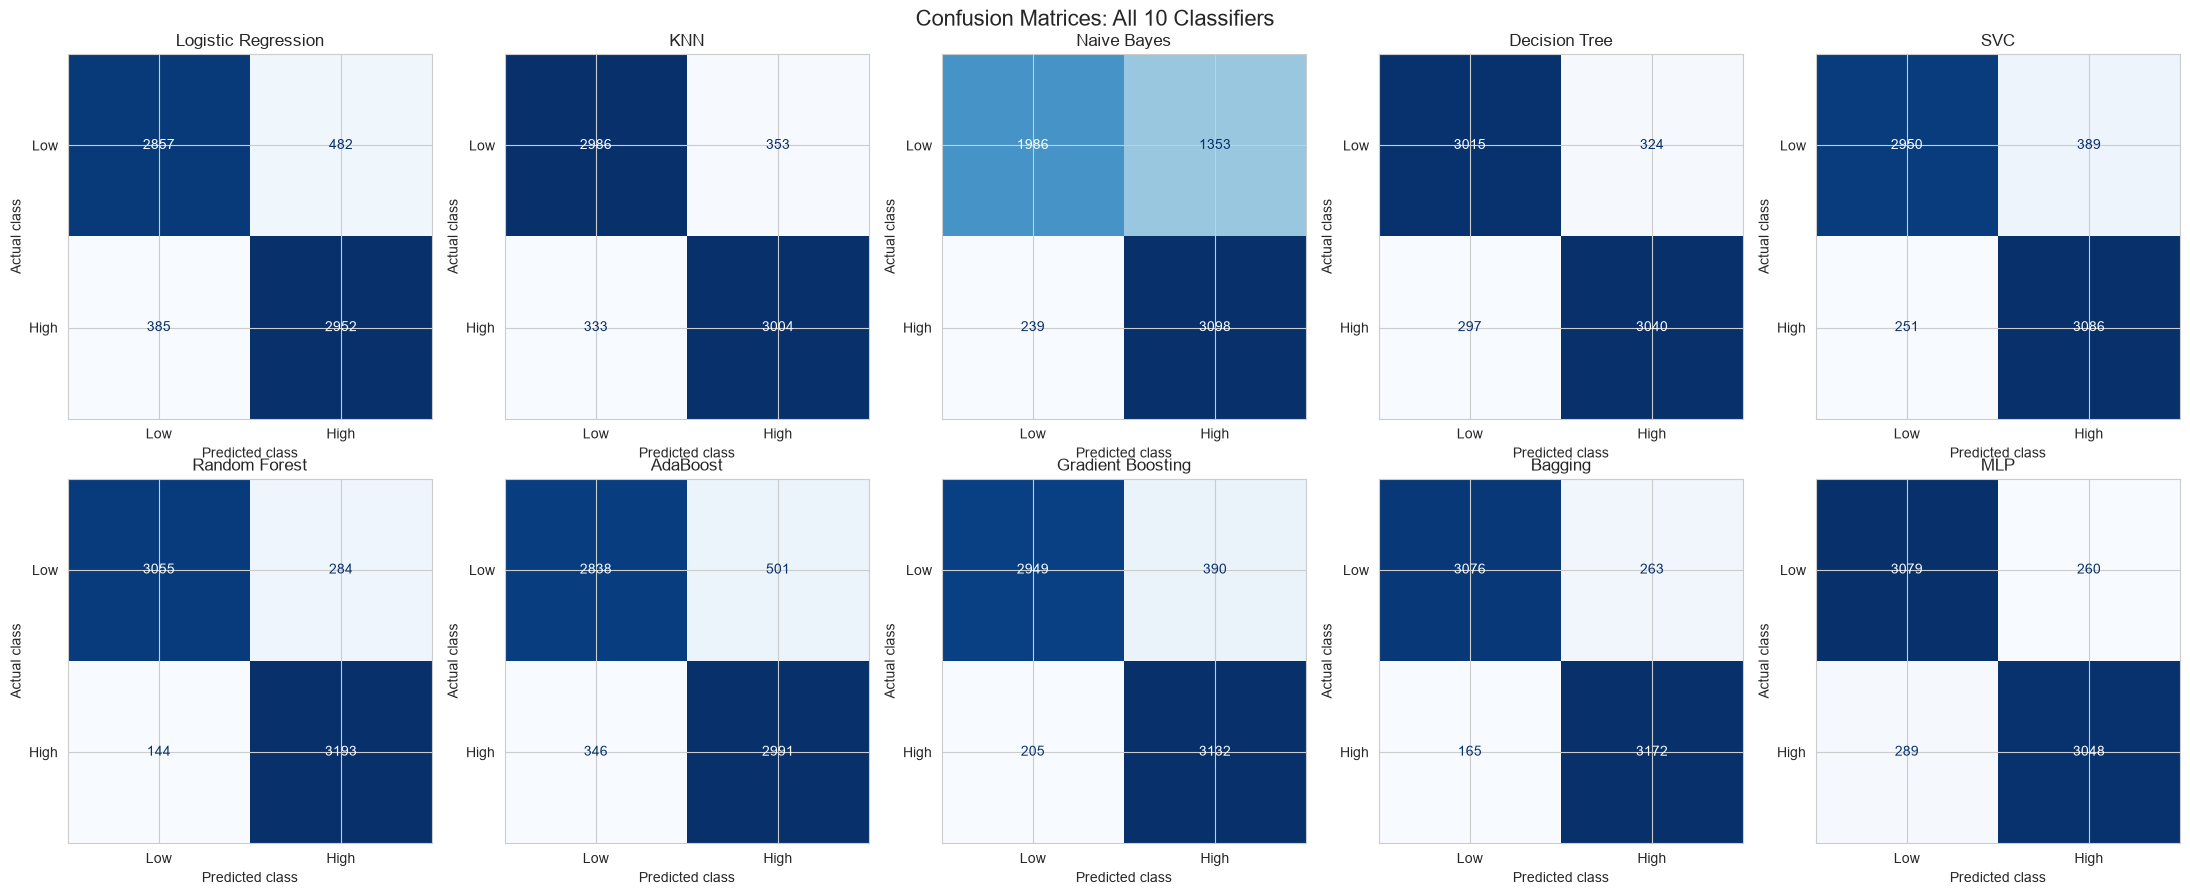

In [24]:
fig, axes = plt.subplots(2, 5, figsize=(22, 9))
for ax, name in zip(axes.flatten(), models):
    ConfusionMatrixDisplay.from_predictions(
        y_test, preds[name], display_labels=["Low", "High"],
        ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(name)
    ax.set_xlabel("Predicted class")
    ax.set_ylabel("Actual class")
plt.suptitle("Confusion Matrices: All 10 Classifiers", fontsize=16)
plt.tight_layout()
plt.show()

#### Observations: confusion matrices

- Most models make **errors in both directions at a similar rate**. For example, Bagging has 263 false positives and 165 false negatives, and the MLP has 260 and 289.
- **Random Forest misses the fewest High-demand hours** (only 144 false negatives, with 284 false positives), which matters if the goal is to avoid missing busy hours.
- **Naive Bayes is badly biased towards "High":** it produces 1,353 false positives (Low hours wrongly called High) against only 239 false negatives.
- Logistic Regression (482 false positives, 385 false negatives) and AdaBoost (501 and 346) make clearly more errors of both kinds, consistent with their lower accuracy.

---
## 9. Hyperparameter Tuning

Tuning is applied to the two most relevant models: **Random Forest** (the best baseline, which overfits) and **Gradient Boosting** (a boosting model that does not overfit yet and has room to improve). Each search runs on the full pipeline, so the scaler and encoder are refitted inside every fold, and the scoring metric is weighted F1.

### 9.1 Random Forest: GridSearchCV

18 parameter combinations (3 values of `n_estimators` x 3 of `max_depth` x 2 of `min_samples_leaf`) are tested with 3-fold stratified cross-validation, which gives 54 fits.

In [25]:
from sklearn.model_selection import StratifiedKFold
cv3 = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

rf_pipe = Pipeline([("prep", clone(preprocessor)),
                    ("model", RandomForestClassifier(random_state=RANDOM_STATE))])

rf_grid = {
    "model__n_estimators": [100, 200, 300],
    "model__max_depth": [None, 20, 30],
    "model__min_samples_leaf": [1, 2],
}

rf_search = GridSearchCV(rf_pipe, rf_grid, cv=cv3, scoring="f1_weighted",
                         n_jobs=-1, verbose=1)
start = time.time()
rf_search.fit(X_train, y_train)
print("Best params:", rf_search.best_params_)
print("Best CV F1 :", round(rf_search.best_score_, 4))
print(f"Time: {time.time() - start:.0f}s")

Fitting 3 folds for each of 18 candidates, totalling 54 fits
Best params: {'model__max_depth': 30, 'model__min_samples_leaf': 1, 'model__n_estimators': 300}
Best CV F1 : 0.9309
Time: 115s


#### Observations: Random Forest tuning

- Best parameters: `n_estimators=300`, `max_depth=30`, `min_samples_leaf=1`, with a best 3-fold CV F1 of **0.9309** (115 s).
- The best setting is the largest forest and the deepest trees in the grid, so Random Forest benefits from complexity but has probably reached its ceiling. Section 9.3 shows that this did not improve the test score.

### 9.2 Gradient Boosting: RandomizedSearchCV

The grid has 54 combinations (3 x 3 x 3 x 2 for `n_estimators`, `learning_rate`, `max_depth` and `subsample`). To save time, 12 random combinations are sampled and each is evaluated with 3-fold CV, which gives 36 fits.

In [26]:
gb_pipe = Pipeline([("prep", clone(preprocessor)),
                    ("model", GradientBoostingClassifier(random_state=RANDOM_STATE))])

gb_grid = {
    "model__n_estimators": [100, 200, 300],
    "model__learning_rate": [0.05, 0.1, 0.2],
    "model__max_depth": [3, 5, 7],
    "model__subsample": [0.8, 1.0],
}

gb_search = RandomizedSearchCV(gb_pipe, gb_grid, n_iter=12, cv=cv3,
                               scoring="f1_weighted", n_jobs=-1,
                               random_state=RANDOM_STATE, verbose=1)
start = time.time()
gb_search.fit(X_train, y_train)
print("Best params:", gb_search.best_params_)
print("Best CV F1 :", round(gb_search.best_score_, 4))
print(f"Time: {time.time() - start:.0f}s")

Fitting 3 folds for each of 12 candidates, totalling 36 fits
Best params: {'model__subsample': 0.8, 'model__n_estimators': 200, 'model__max_depth': 7, 'model__learning_rate': 0.1}
Best CV F1 : 0.9367
Time: 226s


#### Observations: Gradient Boosting tuning

- Best parameters: `n_estimators=200`, `learning_rate=0.1`, `max_depth=7`, `subsample=0.8`, with a best 3-fold CV F1 of **0.9367** (226 s).
- The search chose much deeper trees (7 instead of the default 3). Deeper trees let boosting capture the interactions between hour, working day and weather that shallow trees miss. A subsample of 0.8 adds randomness that helps regularise the model.

### 9.3 Before vs after tuning (held-out test set)

The tuned and default models are compared on the same test set.

In [27]:
def test_metrics(pipe):
    y_pred = pipe.predict(X_test)
    score = (pipe.predict_proba(X_test)[:, 1] if hasattr(pipe, "predict_proba")
             else pipe.decision_function(X_test))
    return {"Accuracy": accuracy_score(y_test, y_pred),
            "F1-score": f1_score(y_test, y_pred, average="weighted"),
            "ROC-AUC": roc_auc_score(y_test, score),
            "Train Acc": pipe.score(X_train, y_train)}

best_rf = rf_search.best_estimator_
best_gb = gb_search.best_estimator_

tuning_df = pd.DataFrame({
    "Random Forest (default)": test_metrics(fitted["Random Forest"]),
    "Random Forest (tuned)": test_metrics(best_rf),
    "Gradient Boosting (default)": test_metrics(fitted["Gradient Boosting"]),
    "Gradient Boosting (tuned)": test_metrics(best_gb),
}).T
tuning_df.round(4)

,Accuracy,F1-score,ROC-AUC,Train Acc
Random Forest (default),0.9359,0.9359,0.9838,1.0000
Random Forest (tuned),0.9353,0.9353,0.9843,1.0000
Gradient Boosting (default),0.9109,0.9108,0.9694,0.9150
Gradient Boosting (tuned),0.9458,0.9458,0.9856,0.9912


#### Observations: effect of tuning

| Model | Accuracy | F1 | ROC-AUC | Train accuracy |
|:---|---:|---:|---:|---:|
| Random Forest (default) | 0.9359 | 0.9359 | 0.9838 | 1.0000 |
| Random Forest (tuned) | 0.9353 | 0.9353 | 0.9843 | 1.0000 |
| Gradient Boosting (default) | 0.9109 | 0.9108 | 0.9694 | 0.9150 |
| **Gradient Boosting (tuned)** | **0.9458** | **0.9458** | **0.9856** | 0.9912 |

- **Gradient Boosting improved substantially**: F1 rose from 0.9108 to 0.9458 (+3.5 points) and ROC-AUC from 0.9694 to 0.9856. It is now the best model.
- **Random Forest did not improve**: F1 changed by only -0.0006 and ROC-AUC by +0.0005. It was already close to its limit, so the default was nearly optimal.
- Tuned Gradient Boosting now fits the training data much more closely (0.9912 vs 0.9150 train accuracy), so a gap of about 4.5 points to the test score remains.

---
## 10. Cross-Validation

Stratified **5-fold cross-validation** is run on the training set for the two best models (tuned Gradient Boosting and tuned Random Forest). It checks that the test-set result is not just a lucky split. The test set is left untouched.

In [28]:
from sklearn.model_selection import cross_validate

cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {"accuracy": "accuracy", "f1": "f1_weighted", "roc_auc": "roc_auc"}

top_two = {"Gradient Boosting (tuned)": best_gb,
           "Random Forest (tuned)": best_rf}

cv_rows, fold_f1 = [], {}
for name, mdl in top_two.items():
    res = cross_validate(clone(mdl), X_train, y_train, cv=cv5,
                         scoring=scoring, n_jobs=-1)
    fold_f1[name] = res["test_f1"]
    cv_rows.append({
        "Model": name,
        "CV Accuracy": f"{res['test_accuracy'].mean():.4f} ± {res['test_accuracy'].std():.4f}",
        "CV F1": f"{res['test_f1'].mean():.4f} ± {res['test_f1'].std():.4f}",
        "CV ROC-AUC": f"{res['test_roc_auc'].mean():.4f} ± {res['test_roc_auc'].std():.4f}",
    })

cv_df = pd.DataFrame(cv_rows).set_index("Model")
display(cv_df)

print("\nPer-fold F1 scores:")
for name, scores in fold_f1.items():
    print(f"{name}: {np.round(scores, 4)}")

,CV Accuracy,CV F1,CV ROC-AUC
Model,,,
Gradient Boosting (tuned),0.9390 ± 0.0036,0.9390 ± 0.0036,0.9845 ± 0.0012
Random Forest (tuned),0.9339 ± 0.0033,0.9339 ± 0.0033,0.9826 ± 0.0015



Per-fold F1 scores:
Gradient Boosting (tuned): [0.9403 0.939  0.9438 0.9326 0.9393]
Random Forest (tuned): [0.9367 0.9335 0.938  0.9285 0.9329]


#### Observations: cross-validation

| Model | CV accuracy | CV F1 | CV ROC-AUC |
|:---|:---:|:---:|:---:|
| Gradient Boosting (tuned) | 0.9390 +/- 0.0036 | 0.9390 +/- 0.0036 | 0.9845 +/- 0.0012 |
| Random Forest (tuned) | 0.9339 +/- 0.0033 | 0.9339 +/- 0.0033 | 0.9826 +/- 0.0015 |

- **Gradient Boosting scored higher than Random Forest in all five folds** (for example 0.9403 vs 0.9367 in fold 1 and 0.9326 vs 0.9285 in fold 4), so the ranking is consistent and not luck.
- The small standard deviations (about 0.003) show both models are stable across folds.
- The CV F1 of Gradient Boosting (0.9390) is slightly lower than its single test score (0.9458), so the test split was a little favourable. The CV figure is the more conservative estimate of real performance.

---
## 11. Further Visualisations

### 11.1 ROC curves

ROC curves for all ten baseline models, with the tuned Gradient Boosting highlighted as a thick dashed line. The closer a curve is to the top-left corner, the better the model separates the two classes.

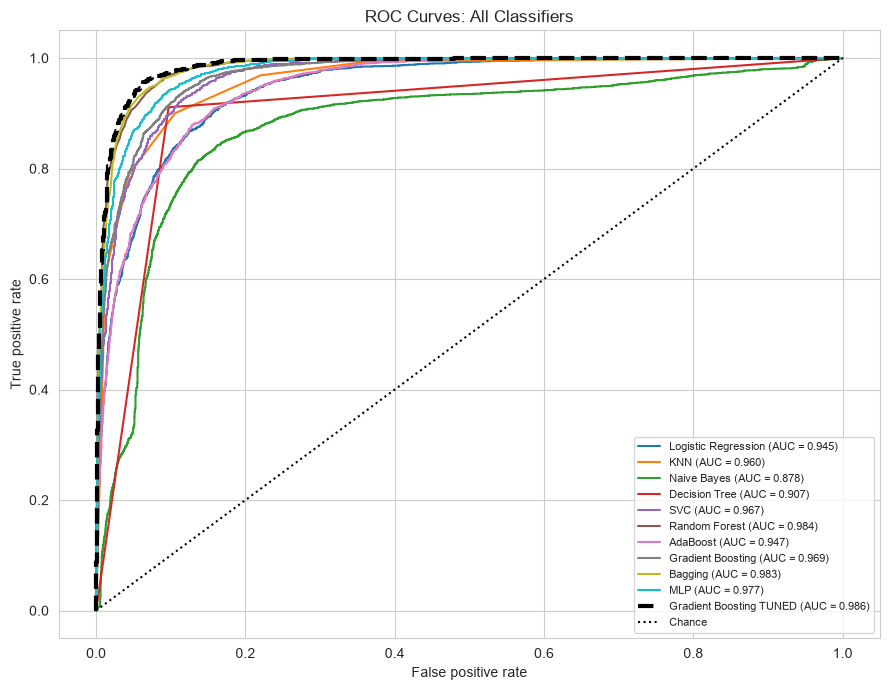

In [29]:
plt.figure(figsize=(9, 7))
colors = sns.color_palette("tab10", 10)

for (name, pipe), c in zip(fitted.items(), colors):
    score = (pipe.predict_proba(X_test)[:, 1] if hasattr(pipe, "predict_proba")
             else pipe.decision_function(X_test))
    fpr, tpr, _ = roc_curve(y_test, score)
    plt.plot(fpr, tpr, color=c, lw=1.5,
             label=f"{name} (AUC = {roc_auc_score(y_test, score):.3f})")

score = best_gb.predict_proba(X_test)[:, 1]
fpr, tpr, _ = roc_curve(y_test, score)
plt.plot(fpr, tpr, color="black", lw=3, linestyle="--",
         label=f"Gradient Boosting TUNED (AUC = {roc_auc_score(y_test, score):.3f})")

plt.plot([0, 1], [0, 1], "k:", label="Chance")
plt.title("ROC Curves: All Classifiers")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.show()

#### Observations: ROC curves

- **Tuned Gradient Boosting (AUC 0.986) has the best curve**, hugging the top-left corner, followed closely by Random Forest (0.984), Bagging (0.983) and MLP (0.977).
- Gradient Boosting (0.969), SVC (0.967), KNN (0.960), AdaBoost (0.947) and Logistic Regression (0.945) form a middle group.
- The **Decision Tree curve is made of a few straight segments** (AUC 0.907) because a single tree produces only a handful of distinct probability values.
- **Naive Bayes is the lowest** (AUC 0.878) and its curve sags well below the others: it needs a much higher false-positive rate to reach the same true-positive rate.
- Every model is far above the diagonal chance line, so all of them learned real structure in the data.

### 11.2 Feature importance (tuned Gradient Boosting)

The top 15 features ranked by how much they contribute to the tuned Gradient Boosting model's decisions.

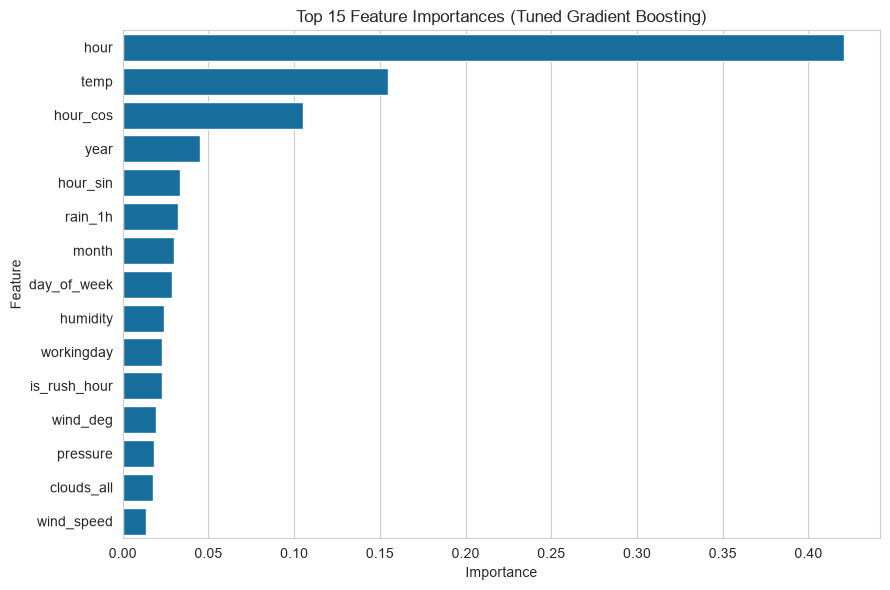

In [30]:
feat_names = [n.split("__", 1)[1] for n in best_gb.named_steps["prep"].get_feature_names_out()]
imp = (pd.Series(best_gb.named_steps["model"].feature_importances_, index=feat_names)
       .sort_values(ascending=False).head(15))

plt.figure(figsize=(9, 6))
sns.barplot(x=imp.values, y=imp.index, orient="h", color=sns.color_palette("colorblind")[0])
plt.title("Top 15 Feature Importances (Tuned Gradient Boosting)")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

#### Observations: feature importance

- **`hour` is by far the most important feature** (about 0.42), confirming what the demand-by-hour plot showed.
- **`temp` is second** (about 0.15) and `hour_cos` third (about 0.10). Together the three time-of-day features (`hour`, `hour_cos`, `hour_sin`) account for roughly 0.56 of the total importance.
- Next come `year`, `rain_1h`, `month` and `day_of_week` (each about 0.03-0.05).
- Humidity, working day, rush-hour flag, wind direction, pressure, cloud cover and wind speed each contribute only about 0.015-0.025.
- `is_rush_hour` ranks low because `hour` already carries the same information, which is expected when one feature includes another.
- In short, the model is driven mainly by time of day and temperature, while most other weather variables add little.

### 11.3 Decision Tree: effect of `max_depth` and tree visualisation

The first plot sweeps `max_depth` from 2 to 20 and compares the training and validation F1 (3-fold CV). The second plot draws a small tree (`max_depth=3`) so its decisions are readable. The tree shows **standardised** feature values, because the pipeline scales the features before the tree sees them.

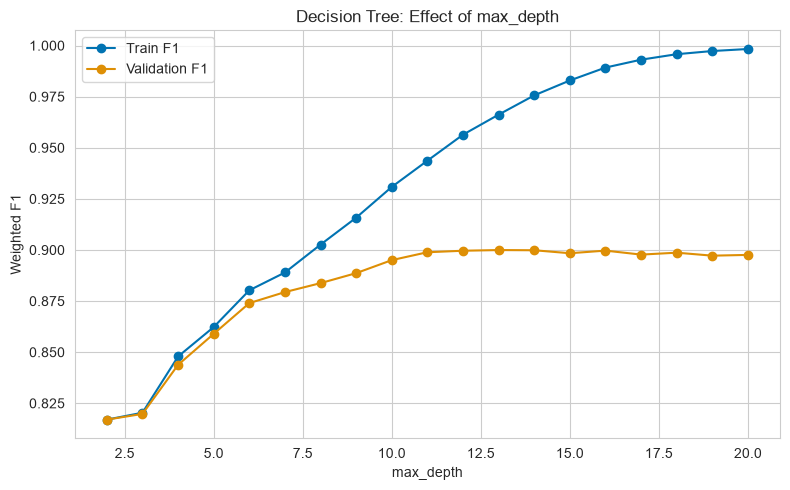

Best max_depth by validation F1: 13


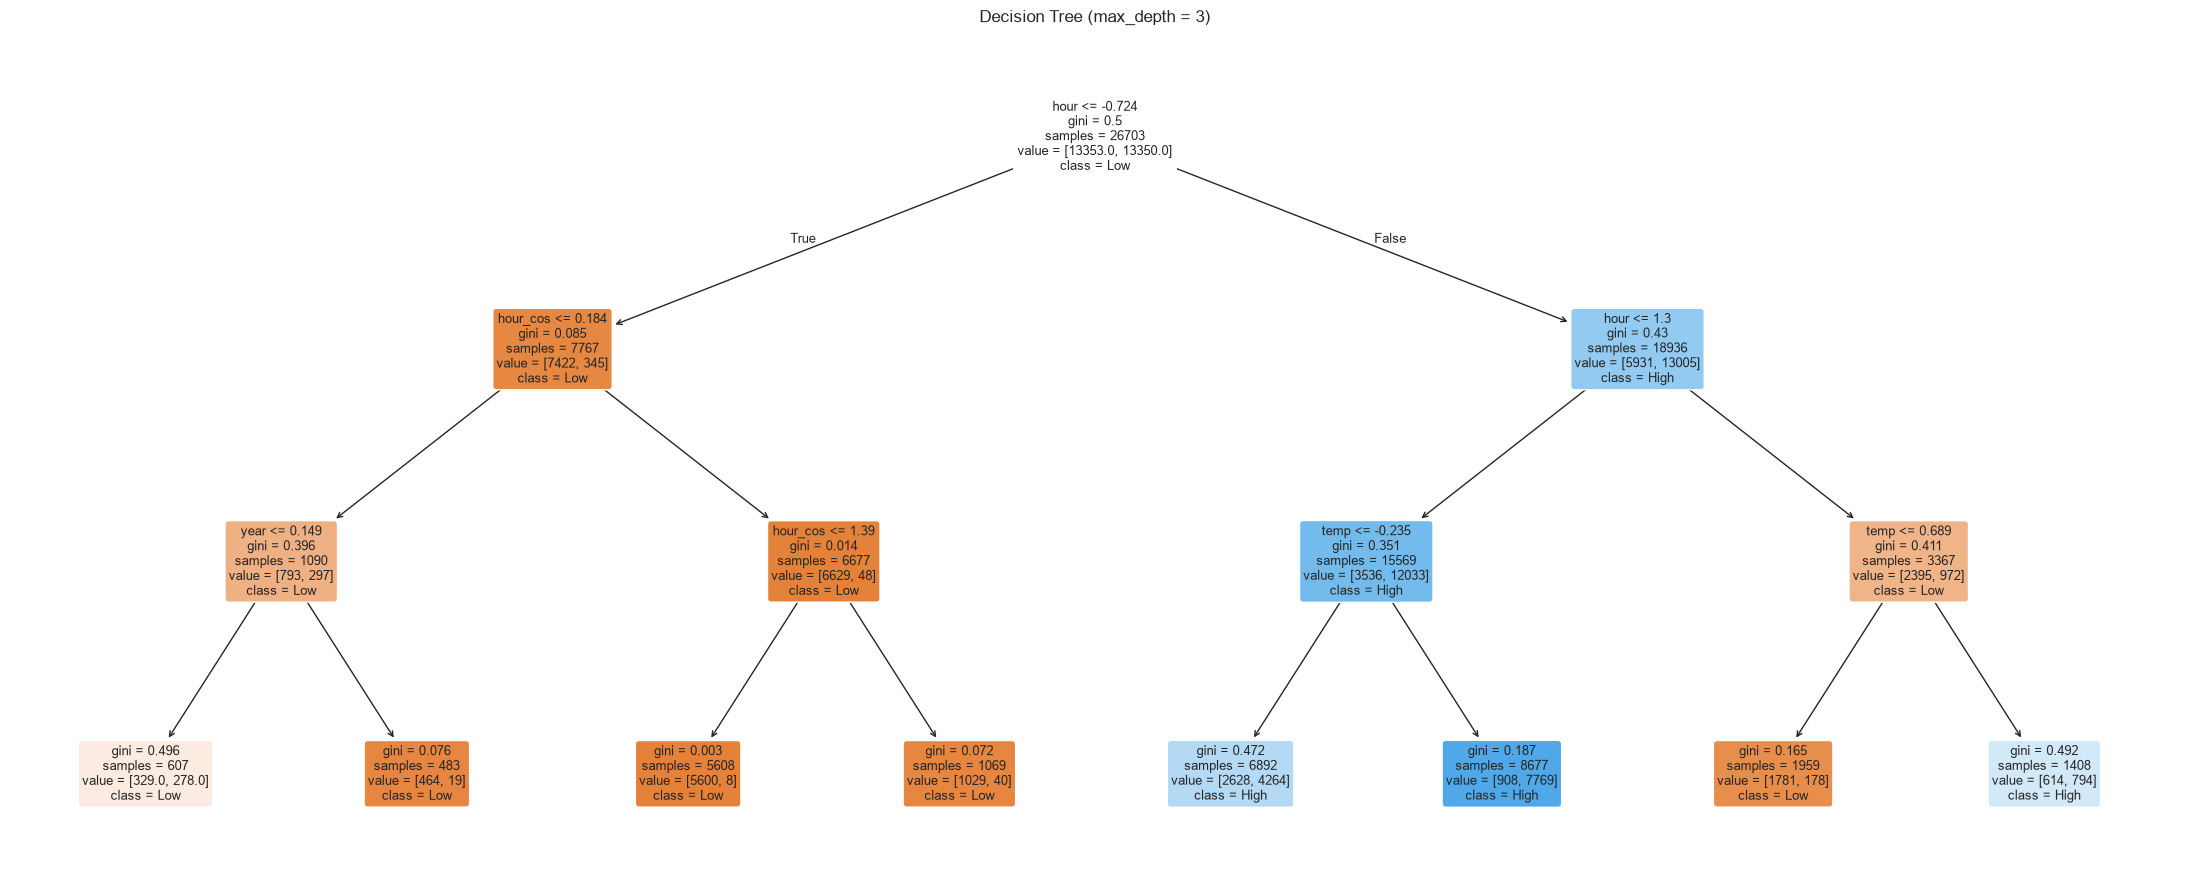

In [31]:
from sklearn.model_selection import validation_curve

depths = list(range(2, 21))
dt_pipe = Pipeline([("prep", clone(preprocessor)),
                    ("model", DecisionTreeClassifier(random_state=RANDOM_STATE))])

train_sc, val_sc = validation_curve(dt_pipe, X_train, y_train,
                                    param_name="model__max_depth", param_range=depths,
                                    cv=cv3, scoring="f1_weighted", n_jobs=-1)

plt.figure(figsize=(8, 5))
plt.plot(depths, train_sc.mean(axis=1), marker="o", label="Train F1")
plt.plot(depths, val_sc.mean(axis=1), marker="o", label="Validation F1")
plt.title("Decision Tree: Effect of max_depth")
plt.xlabel("max_depth")
plt.ylabel("Weighted F1")
plt.legend()
plt.tight_layout()
plt.show()

print("Best max_depth by validation F1:", depths[val_sc.mean(axis=1).argmax()])

# Readable tree (depth 3)
dt_small = Pipeline([("prep", clone(preprocessor)),
                     ("model", DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE))])
dt_small.fit(X_train, y_train)
dt_names = [n.split("__", 1)[1] for n in dt_small.named_steps["prep"].get_feature_names_out()]

plt.figure(figsize=(22, 9))
plot_tree(dt_small.named_steps["model"], feature_names=dt_names,
          class_names=["Low", "High"], filled=True, rounded=True, fontsize=9)
plt.title("Decision Tree (max_depth = 3)")
plt.tight_layout()
plt.show()

#### Observations: decision tree

**max_depth sweep**
- Training F1 climbs steadily towards 1.0 as the tree gets deeper, while validation F1 rises only until about depth 11-13 and then stays flat at about 0.90. The best validation depth is **13**.
- The widening gap beyond that depth is a clear picture of **overfitting**: deeper trees memorise the training data without generalising better. This explains the 1.0000 training accuracy of the default Decision Tree.

**Tree structure**
- The very first split is on `hour` (standardised value <= -0.724, which corresponds to the early hours of the day). The left branch holds 7,767 hours of which 7,422 (about 96%) are Low demand, confirming that early hours are Low demand.
- The right branch (18,936 hours, 13,005 of them High) is split again on `hour` and then on temperature.
- The purest High leaf contains 8,677 hours of which 7,769 (about 90%) are High demand: daytime/evening hours with higher temperature. The purest Low leaf holds 5,608 hours of which 5,600 are Low demand: the early hours.
- Only `hour`, `hour_cos`, `year` and `temp` are used in the first three levels, matching the feature-importance ranking.

---
## 12. Final Comparison, Conclusion & Saved Model

### 12.1 Final consolidated table

All ten algorithms plus the two tuned models, ranked by weighted F1 on the held-out test set.

In [32]:
def full_metrics(name, part, pipe):
    y_pred = pipe.predict(X_test)
    score = (pipe.predict_proba(X_test)[:, 1] if hasattr(pipe, "predict_proba")
             else pipe.decision_function(X_test))
    return {"Algorithm": name, "Part": part,
            "Train Acc": pipe.score(X_train, y_train),
            "Accuracy": accuracy_score(y_test, y_pred),
            "Precision": precision_score(y_test, y_pred, average="weighted"),
            "Recall": recall_score(y_test, y_pred, average="weighted"),
            "F1-score": f1_score(y_test, y_pred, average="weighted"),
            "ROC-AUC": roc_auc_score(y_test, score)}

tuned_rows = [full_metrics("Random Forest (tuned)", "B", best_rf),
              full_metrics("Gradient Boosting (tuned)", "B", best_gb)]

final_df = (pd.concat([results_df.drop(columns=["Time (s)"]), pd.DataFrame(tuned_rows)],
                      ignore_index=True)
            .sort_values("F1-score", ascending=False).reset_index(drop=True))
final_df.index += 1
final_df.round(4)

,Algorithm,Part,Train Acc,Accuracy,Precision,Recall,F1-score,ROC-AUC
1,Gradient Boosting (tuned),B,0.9912,0.9458,0.9462,0.9458,0.9458,0.9856
2,Bagging,B,0.9999,0.9359,0.9363,0.9359,0.9359,0.9832
3,Random Forest,B,1.0000,0.9359,0.9367,0.9359,0.9359,0.9838
4,Random Forest (tuned),B,1.0000,0.9353,0.9361,0.9353,0.9353,0.9843
5,MLP,B,0.9682,0.9178,0.9178,0.9178,0.9178,0.9767
6,Gradient Boosting,B,0.9150,0.9109,0.9121,0.9109,0.9108,0.9694
7,Decision Tree,A,1.0000,0.9070,0.9070,0.9070,0.9070,0.9070
8,SVC,A,0.9195,0.9041,0.9048,0.9041,0.9041,0.9668
9,KNN,A,0.9378,0.8972,0.8973,0.8972,0.8972,0.9603
10,AdaBoost,B,0.8798,0.8731,0.8739,0.8731,0.8731,0.9471


#### Observations: final table

- **Tuned Gradient Boosting ranks first** (accuracy and F1 0.9458, ROC-AUC 0.9856).
- Bagging, Random Forest and tuned Random Forest follow at F1 0.9353-0.9359. Tuning did not help Random Forest.
- The table has 12 rows: the 10 required algorithms (Part A and Part B) and the 2 tuned versions.
- Naive Bayes remains last (F1 0.7547).

### 12.2 Conclusion and final model selection

**Final model: tuned Gradient Boosting** (`n_estimators=200`, `learning_rate=0.1`, `max_depth=7`, `subsample=0.8`).

**Why this model**
- It has the **best test performance**: accuracy and F1 0.9458, ROC-AUC 0.9856, up from F1 0.9108 before tuning.
- It is **reliable**: 5-fold CV F1 of 0.9390 +/- 0.0036, higher than tuned Random Forest (0.9339 +/- 0.0033) in all five folds.
- Boosting builds trees one after another, each correcting the errors of the previous ones. This suits the interactions between hour, working day, temperature and weather in this data.

**Key findings**
- Time of day is the dominant driver of demand, followed by temperature. Most other weather variables add little.
- Tree-ensemble methods (Gradient Boosting, Random Forest, Bagging) clearly beat linear and probabilistic models, which cannot capture the non-linear patterns.
- Naive Bayes performed worst because its independence assumption does not hold for this data.

**Limitations and trade-offs**
- **Random split on time-series data:** the data is an hourly time series but a random stratified split was used, so neighbouring hours can fall in both the training and the test set. Scores may therefore be somewhat optimistic. A time-based split (train on earlier years, test on later ones) would give a more realistic estimate.
- **Repeated timestamps:** 1,686 hours appear 2-4 times with the same ride count (Section 4.1). Copies of the same hour can land in both sets, which also favours models that memorise (Random Forest, Bagging, Decision Tree, KNN). Splitting by timestamp (for example `GroupShuffleSplit`) would remove this effect.
- **Remaining overfitting:** tuned Gradient Boosting reaches 99.1% training accuracy against 94.6% on the test set. More regularisation (shallower trees, early stopping) could narrow this gap.
- **Binary target:** the model predicts whether an hour is busy (above the median), not how many rides to expect.

### 12.3 Save the final model

The tuned Gradient Boosting pipeline (preprocessing and classifier together) is saved with `joblib`. It is reloaded straight away to confirm that it reproduces the same test score.

In [33]:
import os, joblib

os.makedirs("models", exist_ok=True)                       # creates a "models" folder
joblib.dump(best_gb, "models/final_gradient_boosting.pkl")  # saves the model

# Check: reload it and confirm it gives the same score as before
loaded = joblib.load("models/final_gradient_boosting.pkl")
print("Reloaded model test F1:",
      round(f1_score(y_test, loaded.predict(X_test), average="weighted"), 4))

Reloaded model test F1: 0.9458


#### Observations: saved model

- The reloaded model gives a test F1 of **0.9458**, identical to the tuned model, so the file was saved and restored correctly.
- The saved pipeline contains the scaler, the encoder and the classifier. New data must already contain the engineered columns (`hour`, `is_rush_hour`, `hour_sin` and so on) and the cleaned values (log-transformed `rain_1h` and `snow_1h`, rare weather types merged into "Other") before calling `predict`.